# DSA211: Diagnosing and Remedying Nonlinearity in Bike-Sharing Demand Models
## Notebook 05: Regularization Extension
**Group 2**: Kok Wai Ying, Lee Sin Yang, Lim Wei Lun Marcus, Samuel Teo Yuzhen, Tee Jing Yuan

> **AI Coding Assistant Declaration**:
> In accordance with course guidelines, an AI coding assistant was used strictly for code scaffolding and plotting functions. All modeling decisions, interpretations, and written commentaries are independently authored by group members in the designated sections below (see [`agents.md`](../agents.md)).


### Planned Steps & Workflow (Referencing `docs/project_cv_workflow.html`)
**Model ladder rungs: Ridge, LASSO** (on the Notebook 04 feature spaces; PCA is not used)
- **1. Setup & High-Dimensional Feature Space**:
  - Load the base processed training dataset (`data/train_base.csv`) and the shared expanding-window CV protocol ($k=8$ monthly folds).
  - Rebuild the Notebook 04 transforms in this notebook (`add_poly`, `hr` $\times$ `workingday`; degree 2 as selected there). Do not touch the locked test set.
  - Regularise two spaces so shrinkage can be compared with the nonlinear terms: **base** (M2 design, 48 columns) and **M4** (74 columns).
- **2. Ridge Regression ($L_2$ Penalty)**:
  - Pipeline: `StandardScaler` (fit on the training window only) $\rightarrow$ `Ridge`.
  - Tune $\lambda$ (`alpha`) on a log-spaced grid using the **same 8 folds** and the **count-scale MSE** used in Notebook 04 (not sklearn `GridSearchCV`, which would score the log-scale fit).
  - Record $\lambda_{\min}$ and $\lambda_{1\text{SE}}$; plot CV error vs. $\log(\lambda)$ and coefficient traces.
- **3. LASSO Regression ($L_1$ Penalty)**:
  - Same protocol with `Lasso`. Ridge and LASSO `alpha` values are not on the same scale.
  - Plot the LASSO path and count which column groups are zeroed at each chosen $\lambda$.
- **4. Analytical Evaluation: Shrinkage vs. Nonlinearity**:
  - Compare residual hour $\times$ working-day profiles and CV scores: penalty on the base space vs. the M4 terms vs. OLS M4.
- **5. CV Results Package for Final Selection**:
  - Export per-fold count-scale MSE (`data/cv_results_05_regularization.csv`) in the same format as Notebook 04 ($\text{CV RMSE} = \sqrt{\text{mean fold MSE}}$, $\text{SE} = \text{SD}/\sqrt{8}$) for Notebook 06.


## 1. Setup and High-Dimensional Feature Space
*Code: Generated by AI Assistant*

This notebook reads the base processed training set only (`data/train_base.csv`, written by Notebook 02). The locked test set is **not** touched (it is read once, in Notebook 06).
- CV protocol: the shared `ExpandingWindowSplit` ($k = 8$ monthly folds, Feb 2012 to Sep 2012) from `src/cv_utils.py`.
- Metric: count-scale MSE, summarised as in Notebook 04: $\text{CV RMSE} = \sqrt{\text{mean fold MSE}}$, $\text{SE} = \text{SD of fold MSEs} / \sqrt{k}$.
- Target for M2–M4 and all regularised models: $\log(cnt)$, back-transformed with $\exp(\hat{y} + \hat{\sigma}^2/2)$ and $\hat{\sigma}^2 = \text{RSS}/(n - p)$ on the training window (same as Notebook 04). M1 stays on `cnt`.
- Feature transforms are **copied from Notebook 04** (`add_poly`, `add_hr_workingday`). Degree 2 is that notebook's CV-selected degree. The fitted M3/M4 squares are **not** mean-centered (centering was used only in 04's degree search).
- Two spaces are regularised:
  - **Base space**: 48 columns (M2 design).
  - **M4 space**: 74 columns (M3 squares + `hr` $\times$ `workingday`).
- OLS M1–M4 are scored on the same folds so the regularised scores can be compared with Notebook 04. M3 (51 columns) is an OLS reference only; it is not regularised.

In [1]:
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import ConvergenceWarning

# Ensure local source modules can be imported
sys.path.append(os.path.abspath('..'))
from src.data_utils import load_train_base, DATA_DIR
from src.cv_utils import get_cv_splitter, FIRST_VAL_MONTH, LAST_VAL_MONTH

sns.set_style('whitegrid')

# Load the base processed training set (written by Notebook 02)
base_df = load_train_base()
print(f"Base training set loaded. Shape: {base_df.shape}")

ID_COLS = ['dteday']
TARGET = 'cnt'
# holiday is an exact combination (weekday_1..5 - workingday): drop it so the design is full rank and workingday stays explicit for hr x workingday
FEATURE_COLS = [c for c in base_df.columns if c not in ID_COLS + [TARGET, 'holiday']]
HR_COLS = [c for c in FEATURE_COLS if c.startswith('hr_')]

# Shared expanding-window CV splitter (identical to Notebooks 02 to 04)
cv_splitter = get_cv_splitter(base_df['dteday'])
K = cv_splitter.get_n_splits()
VAL_MONTHS = [base_df['dteday'].iloc[va].min().strftime('%Y-%m') for _, va in cv_splitter.split(base_df)]
print(f"Shared CV Splitter: ExpandingWindowSplit ({K} monthly folds, {FIRST_VAL_MONTH} to {LAST_VAL_MONTH})")

Base training set loaded. Shape: (15211, 51)
Shared CV Splitter: ExpandingWindowSplit (8 monthly folds, 2012-02 to 2012-09)


In [2]:
# Feature spaces. add_poly / add_hr_workingday are copied from Notebook 04 (fitted M3 / M4).
POLY_COLS = ['temp', 'hum', 'windspeed']
POLY_DEGREE = 2  # Notebook 04 CV-selected degree (best_degree)


def add_poly(X):
    X = X.copy()
    for c in POLY_COLS:
        for d in range(2, POLY_DEGREE + 1):
            X[f'{c}^{d}'] = X[c] ** d
    return X


def add_hr_workingday(X):
    inter = X[HR_COLS].mul(X['workingday'], axis=0)
    inter.columns = [f'{c}:workingday' for c in HR_COLS]
    return pd.concat([X, inter], axis=1)


X_base = base_df[FEATURE_COLS]
X_m3 = add_poly(X_base)
X_m4 = add_hr_workingday(X_m3)
y_all = base_df[TARGET].to_numpy()

# Ridge / LASSO are fit on base (M2 columns) and m4 (final 04 design) only.
FEATURE_SPACES = {'base': X_base, 'm4': X_m4}
OLS_SPACES = {
    'M1': (X_base, False),
    'M2': (X_base, True),
    'M3': (X_m3, True),
    'M4': (X_m4, True),
}
for name, X in [('base', X_base), ('m3', X_m3), ('m4', X_m4)]:
    rank = np.linalg.matrix_rank(np.column_stack([np.ones(len(X)), X.to_numpy(dtype=float)]))
    print(f"{name:<5} space: {X.shape[1]} columns (rank incl. intercept = {rank})")

base  space: 48 columns (rank incl. intercept = 49)
m3    space: 51 columns (rank incl. intercept = 52)
m4    space: 74 columns (rank incl. intercept = 75)


### Interpretation & Modeling Decisions: Setup and Feature Space
**Author**: Lim Wei Lun Marcus

Regularising both the base space (48 columns) and the M4 space (74 columns) separates the effect of the shrinkage penalty from the effect of the engineered features. The base space shows what a penalty achieves on a design with no remedies, while the M4 space tests whether a penalty is still necessary after introducing hr × workingday interactions. The penalty specifically targets variance, such as collinearity among the dummy variables, unstable coefficients and overfitting risk, rather than adding new structural shape to the model. Both spaces are full rank because holiday, an exact combination of the weekday dummies and workingday, is dropped (Notebook 03). The base space is fitted on $\log(cnt)$, so its direct OLS comparator is M2.

## 2. Penalised Fitting and CV Engine
*Code: Generated by AI Assistant*

Each regularised candidate is a pipeline `StandardScaler` $\rightarrow$ `Ridge` or `Lasso`. The scaler is fitted on the training fold only, so no validation-fold information enters the penalty. $\lambda$ is called `alpha` in scikit-learn. OLS references are unscaled `LinearRegression`, matching Notebook 04.
- Ridge minimises $\text{RSS} + \alpha \lVert\beta\rVert_2^2$; LASSO minimises $\frac{1}{2n}\text{RSS} + \alpha \lVert\beta\rVert_1$. The two `alpha` scales are therefore not comparable with each other.
- $\hat{\sigma}^2$ for the back-transformation is the training-fold residual variance on the log scale, with degrees of freedom $n - (\text{number of non-zero coefficients} + 1)$ (all $p + 1$ for Ridge). OLS references use $n - \text{rank}$, as in Notebook 04.
- For every $\lambda$ on the grid, the same 8 expanding-window folds are scored on count-scale MSE (manual loop, not `GridSearchCV`).

In [3]:
warnings.filterwarnings('ignore', category=ConvergenceWarning)


def make_estimator(kind, alpha=None):
    if kind == 'ols':
        return Pipeline([('reg', LinearRegression())])
    reg = Ridge(alpha=alpha) if kind == 'ridge' else Lasso(alpha=alpha, max_iter=20000, precompute=True)
    return Pipeline([('scale', StandardScaler()), ('reg', reg)])


def n_params(est, X_tr, kind):
    # Degrees of freedom used by the fitted model (intercept included)
    if kind == 'ols':
        return np.linalg.matrix_rank(np.column_stack([np.ones(len(X_tr)), X_tr.to_numpy(dtype=float)]))
    if kind == 'ridge':
        return X_tr.shape[1] + 1
    return int(np.count_nonzero(est.named_steps['reg'].coef_)) + 1


def fit_predict_count(kind, alpha, X_tr, y_tr, X_va, log_target=True):
    # Fit on the model's own target scale; return count-scale validation predictions
    est = make_estimator(kind, alpha)
    y_fit = np.log(y_tr) if log_target else y_tr
    est.fit(X_tr, y_fit)
    pred = est.predict(X_va)
    if not log_target:
        return pred, est
    resid = y_fit - est.predict(X_tr)
    sigma2 = float(resid @ resid / (len(y_tr) - n_params(est, X_tr, kind)))
    return np.exp(pred + sigma2 / 2), est


def cv_one(kind, alpha, X, log_target=True):
    # Count-scale MSE per validation fold for one (model, alpha)
    out = []
    for tr, va in cv_splitter.split(base_df):
        pred, est = fit_predict_count(kind, alpha, X.iloc[tr], y_all[tr], X.iloc[va], log_target)
        out.append({'mse': float(np.mean((y_all[va] - pred) ** 2)),
                    'n_nonzero': int(np.count_nonzero(est.named_steps['reg'].coef_))})
    return pd.DataFrame(out)


def summarise(fold_mse):
    m, s = np.mean(fold_mse), np.std(fold_mse, ddof=1)
    return {'cv_mse': m, 'se_mse': s / np.sqrt(len(fold_mse)),
            'cv_rmse': np.sqrt(m), 'se_rmse': (s / np.sqrt(len(fold_mse))) / (2 * np.sqrt(m))}

In [4]:
# OLS reference rungs on the same folds as Notebook 04 (M1 on cnt; M2 / M3 / M4 on log(cnt))
ref_folds = {}
for name, (X, is_log) in OLS_SPACES.items():
    ref_folds[name] = cv_one('ols', None, X, log_target=is_log)['mse'].to_numpy()

print("=== OLS reference rungs (shared CV, count-scale) ===")
print(pd.DataFrame({n: summarise(f) for n, f in ref_folds.items()}).T[['cv_rmse', 'se_rmse', 'cv_mse', 'se_mse']].round(2).to_string())

=== OLS reference rungs (shared CV, count-scale) ===
    cv_rmse  se_rmse    cv_mse   se_mse
M1   130.86     7.19  17125.20  1882.65
M2   186.11    23.58  34635.54  8777.74
M3   151.75    16.84  23028.70  5110.11
M4   115.46    18.95  13330.00  4376.27


### Interpretation & Modeling Decisions: Penalised Fitting and CV Engine
**Author**: Lim Wei Lun Marcus

The StandardScaler is fitted exclusively within each training fold to prevent validation-month information from shaping the penalty. The tuning metric is count-scale CV MSE (reported as RMSE), with log-scale predictions back-transformed first, so all regularized models can be compared directly with the count-scale M1 baseline. The OLS reference scores reproduce the Notebook 04 results (M2 MSE 34,635.54, M3 23,028.70, M4 13,330.00). Comparing a regularized model against its matching OLS rung (same features and target scale) isolates the penalty’s effect. Using the non-zero coefficients (LASSO) or all columns (Ridge) as degrees of freedom for the $\hat{\sigma}^2$ back-transformation is a minor approximation, but with over 9,000 observations per fold the impact is negligible.

## 3. Ridge and LASSO: Tuning $\lambda$ by Shared Expanding-Window CV
*Code: Generated by AI Assistant*

For each of the four models (Ridge / LASSO $\times$ base / M4 space), $\lambda$ runs over a log-spaced grid. Two choices are recorded per model, both fixed by the rule below before anything else is looked at:
- $\lambda_{\min}$: the grid value with the lowest mean CV MSE.
- $\lambda_{1\text{SE}}$: the **largest** $\lambda$ whose mean CV MSE is within one SE of the minimum (SE taken at $\lambda_{\min}$), i.e. the most heavily penalised model that is statistically indistinguishable from the best.

In [5]:
ALPHA_GRIDS = {'ridge': np.logspace(-4, 4, 41),     # Ridge: RSS + alpha * ||b||^2
               'lasso': np.logspace(-5, -0.5, 31)}  # LASSO: RSS / 2n + alpha * ||b||_1

cv_curves = {}   # (kind, space) -> DataFrame indexed by alpha
fold_store = {}  # (kind, space, alpha) -> per-fold MSE

for kind in ['ridge', 'lasso']:
    for space, X in FEATURE_SPACES.items():
        rows = []
        for a in ALPHA_GRIDS[kind]:
            f = cv_one(kind, a, X)
            fold_store[(kind, space, a)] = f['mse'].to_numpy()
            rows.append({'alpha': a, **summarise(f['mse']), 'mean_nonzero': f['n_nonzero'].mean()})
        cv_curves[(kind, space)] = pd.DataFrame(rows).set_index('alpha')
        print(f"done: {kind} / {space}")

done: ridge / base


done: ridge / m4


done: lasso / base


done: lasso / m4


In [6]:
def pick_lambdas(curve):
    # lambda_min: lowest mean CV MSE; lambda_1se: largest alpha within 1 SE of that minimum
    a_min = curve['cv_mse'].idxmin()
    threshold = curve.loc[a_min, 'cv_mse'] + curve.loc[a_min, 'se_mse']
    a_1se = curve.index[curve['cv_mse'] <= threshold].max()
    return a_min, a_1se


chosen = {}
rows = []
for (kind, space), curve in cv_curves.items():
    a_min, a_1se = pick_lambdas(curve)
    chosen[(kind, space)] = {'min': a_min, '1se': a_1se}
    for rule, a in [('min', a_min), ('1se', a_1se)]:
        rows.append({'model': f'{kind}-{space}', 'rule': rule, 'alpha': a,
                     'cv_rmse': curve.loc[a, 'cv_rmse'], 'se_rmse': curve.loc[a, 'se_rmse'],
                     'cv_mse': curve.loc[a, 'cv_mse'], 'se_mse': curve.loc[a, 'se_mse'],
                     'mean_nonzero_coefs': curve.loc[a, 'mean_nonzero']})
tuning_summary = pd.DataFrame(rows).set_index(['model', 'rule'])
print("=== Selected lambda per model (count-scale CV) ===")
print(tuning_summary.round(4).to_string())

# Flag any chosen lambda sitting on the edge of its grid (grid may need widening)
for (kind, space), c in chosen.items():
    g = ALPHA_GRIDS[kind]
    for rule, a in c.items():
        if a in (g[0], g[-1]):
            print(f"WARNING: {kind}/{space} lambda_{rule} = {a:.3g} is at the grid edge")

=== Selected lambda per model (count-scale CV) ===
                     alpha   cv_rmse  se_rmse      cv_mse     se_mse  mean_nonzero_coefs
model      rule                                                                         
ridge-base min   2511.8864  135.5284   6.8937  18367.9450  1868.5730               48.00
           1se   3981.0717  136.7995   6.7075  18714.0956  1835.1548               48.00
ridge-m4   min      0.0001  115.4556  18.9522  13330.0045  4376.2721               74.00
           1se   6309.5734  126.9323   8.0682  16111.8031  2048.2207               74.00
lasso-base min      0.0398  141.9886   9.6132  20160.7614  2729.9376               27.75
           1se      0.0794  149.3489   7.5350  22305.0797  2250.6826               17.25
lasso-m4   min      0.0025  110.6843  17.8980  12251.0157  3962.0482               69.00
           1se      0.0398  122.0306   8.4594  14891.4614  2064.6212               43.00


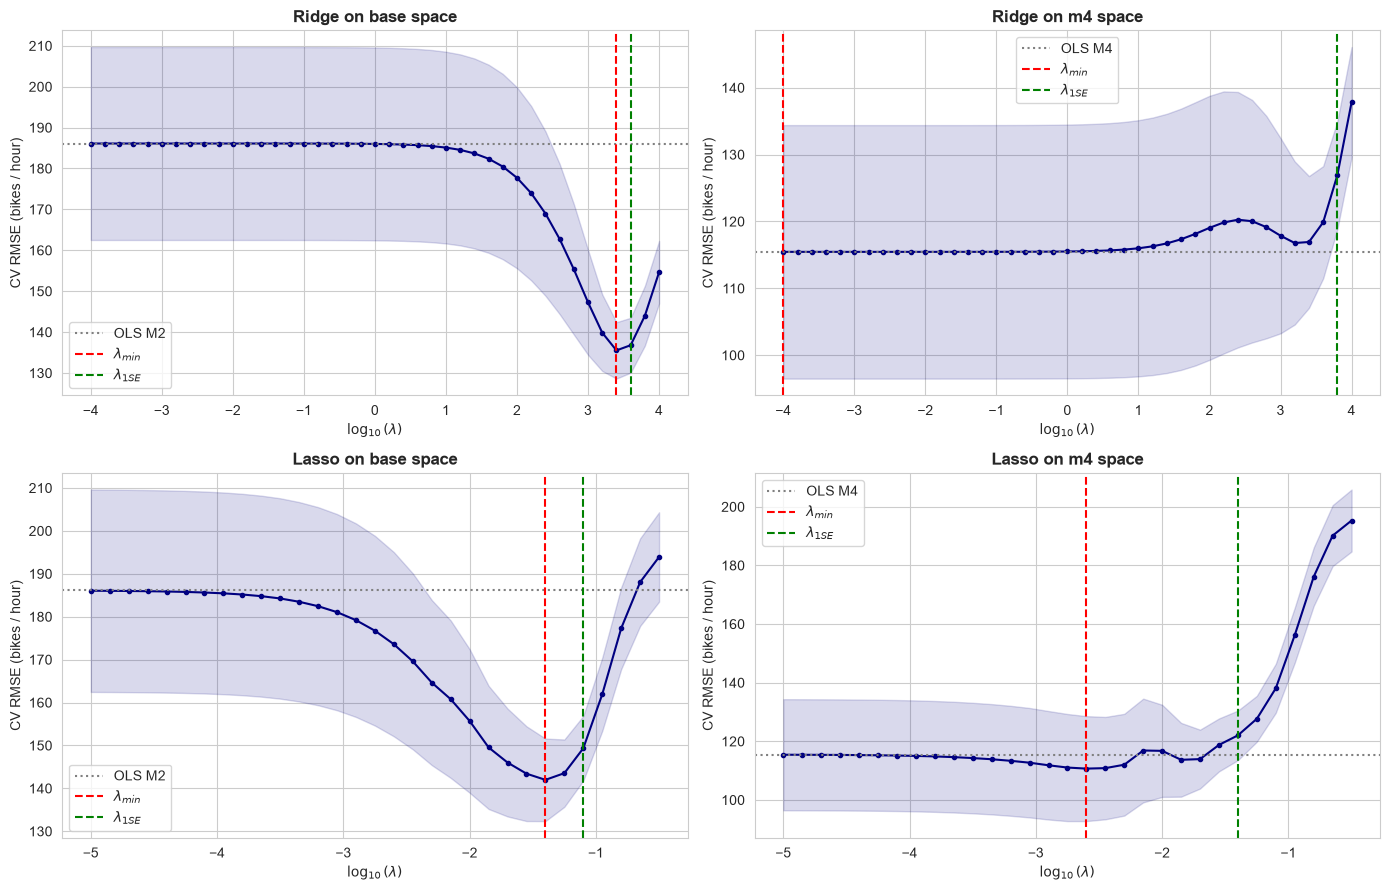

In [7]:
# CV error vs log10(lambda), +/- 1 SE band, with the chosen lambdas and the OLS reference marked
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=False)
for row, kind in enumerate(['ridge', 'lasso']):
    for col, (space, ref) in enumerate([('base', 'M2'), ('m4', 'M4')]):
        ax = axes[row, col]
        curve = cv_curves[(kind, space)]
        x = np.log10(curve.index.to_numpy(dtype=float))
        ax.plot(x, curve['cv_rmse'], marker='o', ms=3, color='navy')
        ax.fill_between(x, curve['cv_rmse'] - curve['se_rmse'], curve['cv_rmse'] + curve['se_rmse'],
                        color='navy', alpha=0.15)
        ax.axhline(summarise(ref_folds[ref])['cv_rmse'], color='gray', linestyle=':', label=f'OLS {ref}')
        ax.axvline(np.log10(chosen[(kind, space)]['min']), color='red', linestyle='--', label=r'$\lambda_{min}$')
        ax.axvline(np.log10(chosen[(kind, space)]['1se']), color='green', linestyle='--', label=r'$\lambda_{1SE}$')
        ax.set_title(f'{kind.capitalize()} on {space} space', fontweight='bold')
        ax.set_xlabel(r'$\log_{10}(\lambda)$'); ax.set_ylabel('CV RMSE (bikes / hour)')
        ax.legend()
plt.tight_layout()
plt.savefig(os.path.join('..', 'figures', '13_lambda_cv_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

### Interpretation & Modeling Decisions: Tuning lambda by CV
**Author**: Lim Wei Lun Marcus

The base-space CV curves form clear U-shapes: CV error falls and then rises as $\lambda$ increases. Ridge and LASSO on the base space lower count-scale CV RMSE relative to OLS M2 (186.11 to 135.53 and 141.99), a paired gain of +1.95 and +1.77 SE. With 8 folds these correspond to p = 0.09 and 0.12 ($t_7$), so neither is a clear gain on its own. Section 6b.1 shows this should not be read as variance reduction: log-scale validation MSE worsens (0.404 to 0.478 and 0.501), while mean predicted / actual falls from 1.32 to 0.94 and 0.95. The gain mainly reflects less over-prediction after back-transformation, and May to July supply 95% and 98% of it (Section 6b.3). Both models still lose to M1 (130.86).

In the M4 space with uncentred squared terms, LASSO gives a smaller improvement over OLS M4 (+1.53 paired SE, p = 0.17, RMSE 110.68 vs 115.46), while Ridge does not improve on OLS: its $\lambda_{\min}$ sits on the lower boundary of the grid (0.0001), where the curve has flattened to the OLS result. This Ridge result depends on how the squared terms are parameterised. Centring them inside each training fold leaves OLS M4 unchanged but lowers CV RMSE to 87.70 for Ridge and 86.58 for LASSO (+1.50 and +1.74 paired SE, Section 6b.6).

The $\lambda_{1\text{SE}}$ rule is weakly informative for LASSO M4: the wide standard error band ($\pm$18 RMSE) permits a much heavier penalty (43 vs 69 active coefficients) at a point estimate of 122.0. The paired difference versus OLS M4 is only −0.31 SE, but this model is better in just 2 of 8 folds and, without May, is worse by 6,143 MSE (Section 6b.3). The large SE appears to reflect month-to-month heterogeneity across folds rather than within-month noise; for example, heavier shrinkage under Ridge M4 at $\lambda_{1\text{SE}}$ lowers RMSE in May through July but raises it in February through April and in August and September.

## 4. Coefficient Paths and Sparsity
*Code: Generated by AI Assistant*

Paths are fitted on the full training set (descriptive only, no test data) over the same grids, using standardised predictors so coefficient sizes are comparable across columns. The sparsity table counts non-zero coefficients at each chosen $\lambda$ and lists the columns LASSO sets to zero.

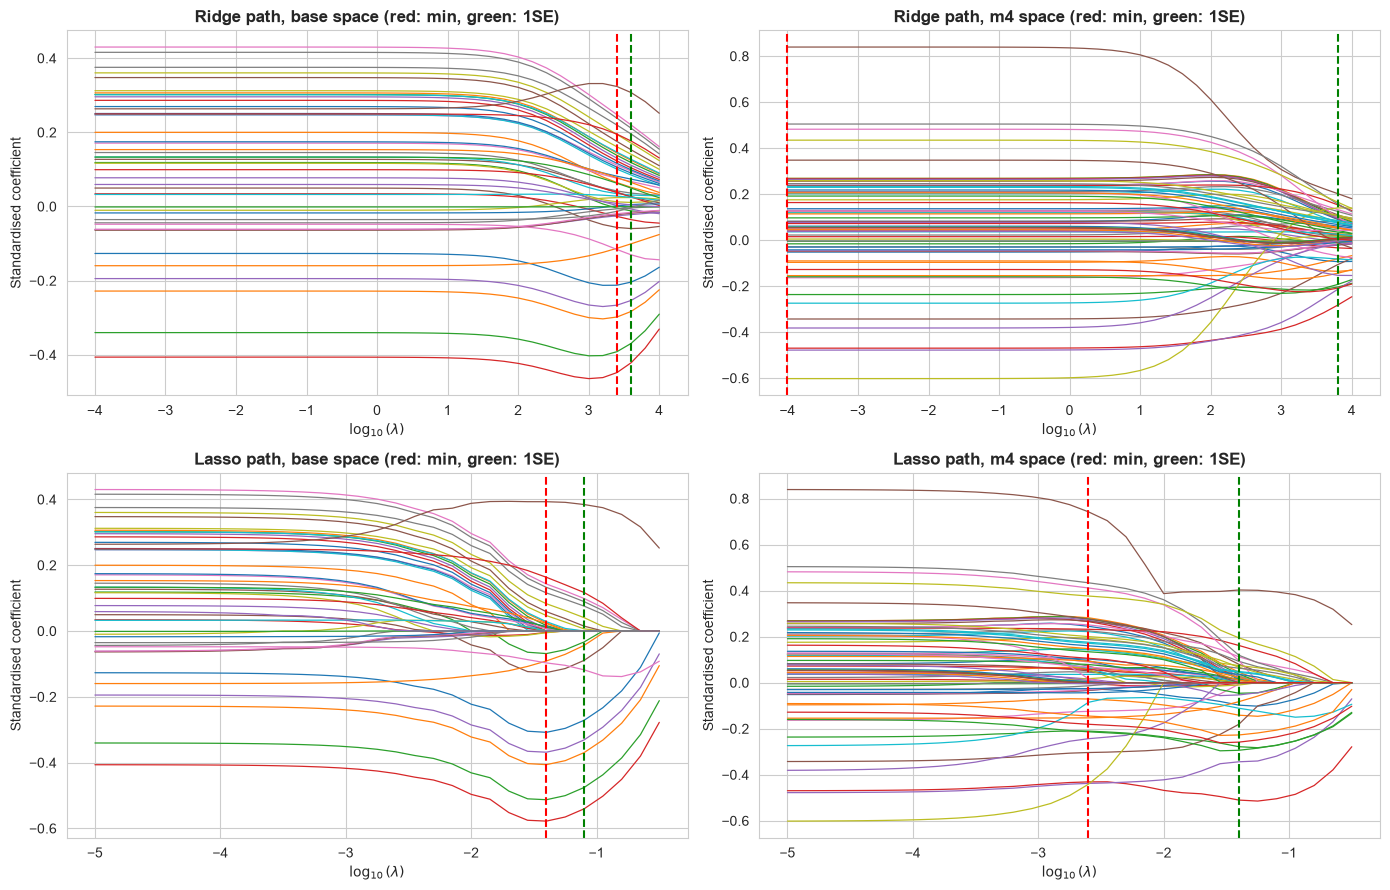

In [8]:
def coef_path(kind, X):
    # Standardised coefficients on the log(cnt) scale, one row per alpha, fitted on all training rows
    out = []
    Xs = StandardScaler().fit_transform(X)
    y_log = np.log(y_all)
    for a in ALPHA_GRIDS[kind]:
        reg = Ridge(alpha=a) if kind == 'ridge' else Lasso(alpha=a, max_iter=20000, precompute=True)
        out.append(reg.fit(Xs, y_log).coef_)
    return pd.DataFrame(out, index=ALPHA_GRIDS[kind], columns=X.columns)


paths = {(kind, space): coef_path(kind, X) for kind in ['ridge', 'lasso'] for space, X in FEATURE_SPACES.items()}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for row, kind in enumerate(['ridge', 'lasso']):
    for col, space in enumerate(['base', 'm4']):
        ax = axes[row, col]
        p = paths[(kind, space)]
        ax.plot(np.log10(p.index.to_numpy(dtype=float)), p.to_numpy(), linewidth=0.9)
        ax.axvline(np.log10(chosen[(kind, space)]['min']), color='red', linestyle='--')
        ax.axvline(np.log10(chosen[(kind, space)]['1se']), color='green', linestyle='--')
        ax.set_title(f'{kind.capitalize()} path, {space} space (red: min, green: 1SE)', fontweight='bold')
        ax.set_xlabel(r'$\log_{10}(\lambda)$'); ax.set_ylabel('Standardised coefficient')
plt.tight_layout()
plt.show()

In [9]:
def column_group(c):
    if ':workingday' in c:
        return 'hr x workingday'
    if '^' in c:
        return 'squared terms'
    for g in ['hr_', 'mnth_', 'weekday_', 'weathersit_']:
        if c.startswith(g):
            return g.rstrip('_')
    return 'other (yr, workingday, temp, hum, windspeed)'


sparsity_rows, zeroed = [], {}
for space, X in FEATURE_SPACES.items():
    groups = pd.Series([column_group(c) for c in X.columns], index=X.columns)
    for rule in ['min', '1se']:
        a = chosen[('lasso', space)][rule]
        coefs = pd.Series(paths[('lasso', space)].loc[a].to_numpy(), index=X.columns)
        zero = coefs.index[coefs == 0]
        zeroed[(space, rule)] = list(zero)
        row = {'space': space, 'rule': rule, 'alpha': a, 'n_nonzero': int((coefs != 0).sum()),
               'n_zero': int((coefs == 0).sum())}
        for g in groups.unique():
            row[f'zero in {g}'] = f"{int((coefs[groups == g] == 0).sum())}/{int((groups == g).sum())}"
        sparsity_rows.append(row)

print("=== LASSO sparsity at the chosen lambdas (full training fit) ===")
print(pd.DataFrame(sparsity_rows).set_index(['space', 'rule']).T.to_string())
for (space, rule), cols in zeroed.items():
    print(f"\nZeroed columns, {space} space, lambda_{rule}: {cols if cols else 'none'}")

=== LASSO sparsity at the chosen lambdas (full training fit) ===
space                                                     base                  m4          
rule                                                       min       1se       min       1se
alpha                                                 0.039811  0.079433  0.002512  0.039811
n_nonzero                                                   27        17        69        43
n_zero                                                      21        31         5        31
zero in hr                                                6/23     10/23      0/23      4/23
zero in mnth                                              5/11     11/11      0/11      5/11
zero in weekday                                            6/6       6/6       0/6       5/6
zero in weathersit                                         2/3       2/3       0/3       2/3
zero in other (yr, workingday, temp, hum, windspeed)       2/5       2/5       1/5       3/5
zero 

In [10]:
# Largest standardised coefficients (absolute value) at lambda_1se, Ridge vs LASSO, M4 space
top = 12
tbl = pd.DataFrame({
    'ridge_1se': paths[('ridge', 'm4')].loc[chosen[('ridge', 'm4')]['1se']],
    'lasso_1se': paths[('lasso', 'm4')].loc[chosen[('lasso', 'm4')]['1se']],
})
print(tbl.reindex(tbl['ridge_1se'].abs().sort_values(ascending=False).index).head(top).round(3).to_string())

                 ridge_1se  lasso_1se
hr_4                -0.283     -0.510
hr_5                -0.214     -0.344
hr_3:workingday     -0.209     -0.258
hr_3                -0.204     -0.278
temp                 0.202      0.403
hr_2:workingday     -0.193     -0.294
hr_8:workingday      0.165      0.195
hr_7:workingday      0.157      0.119
yr                   0.154      0.162
hr_4:workingday     -0.153     -0.053
hr_1:workingday     -0.144     -0.227
temp^2               0.140      0.000


### Interpretation & Modeling Decisions: Coefficient Paths and Sparsity
**Author**: Lim Wei Lun Marcus

LASSO performs feature selection by zeroing out coefficients as the $L_1$ penalty increases, whereas Ridge retains all features (48 in base, 74 in M4) at every $\lambda$, so its $\lambda_{1\text{SE}}$ simply applies heavier shrinkage without producing sparsity. At $\lambda_{\min}$ (0.0025) in the M4 space, LASSO zeroes out about 5 coefficients, leaving roughly 69 active features; at this level the penalty is small, so little sparsity is expected by construction. Pushing LASSO M4 to $\lambda_{1\text{SE}}$ (0.0398) reduces the active feature count to 43. This does not show the removed columns are redundant. The paired difference from OLS M4 (−0.31 SE) is small because the fold differences are noisy: the model is better in only 2 of 8 folds, is worse by 6,143 MSE without May (Section 6b.3), and its largest hour-by-working-day residual rises to 151 from 60 (Section 5). In addition, because LASSO can arbitrarily drop one of two highly correlated columns, the zeroed predictors are not shown to be individually unimportant.

## 5. Shrinkage vs. Nonlinearity: Residual Evidence
*Code: Generated by AI Assistant*

Two views from models fitted on all training rows (diagnostic only, same convention as Notebook 04 Section 6):
- **Mean residual by hour $\times$ working day** (count scale) for OLS and for the $\lambda_{1\text{SE}}$ regularised model in each feature space. This is the pattern that the `hr` $\times$ `workingday` interaction was added to remove.
- **Residuals vs. fitted** (log scale) with a lowess smoother for the same models, to look for remaining curvature.

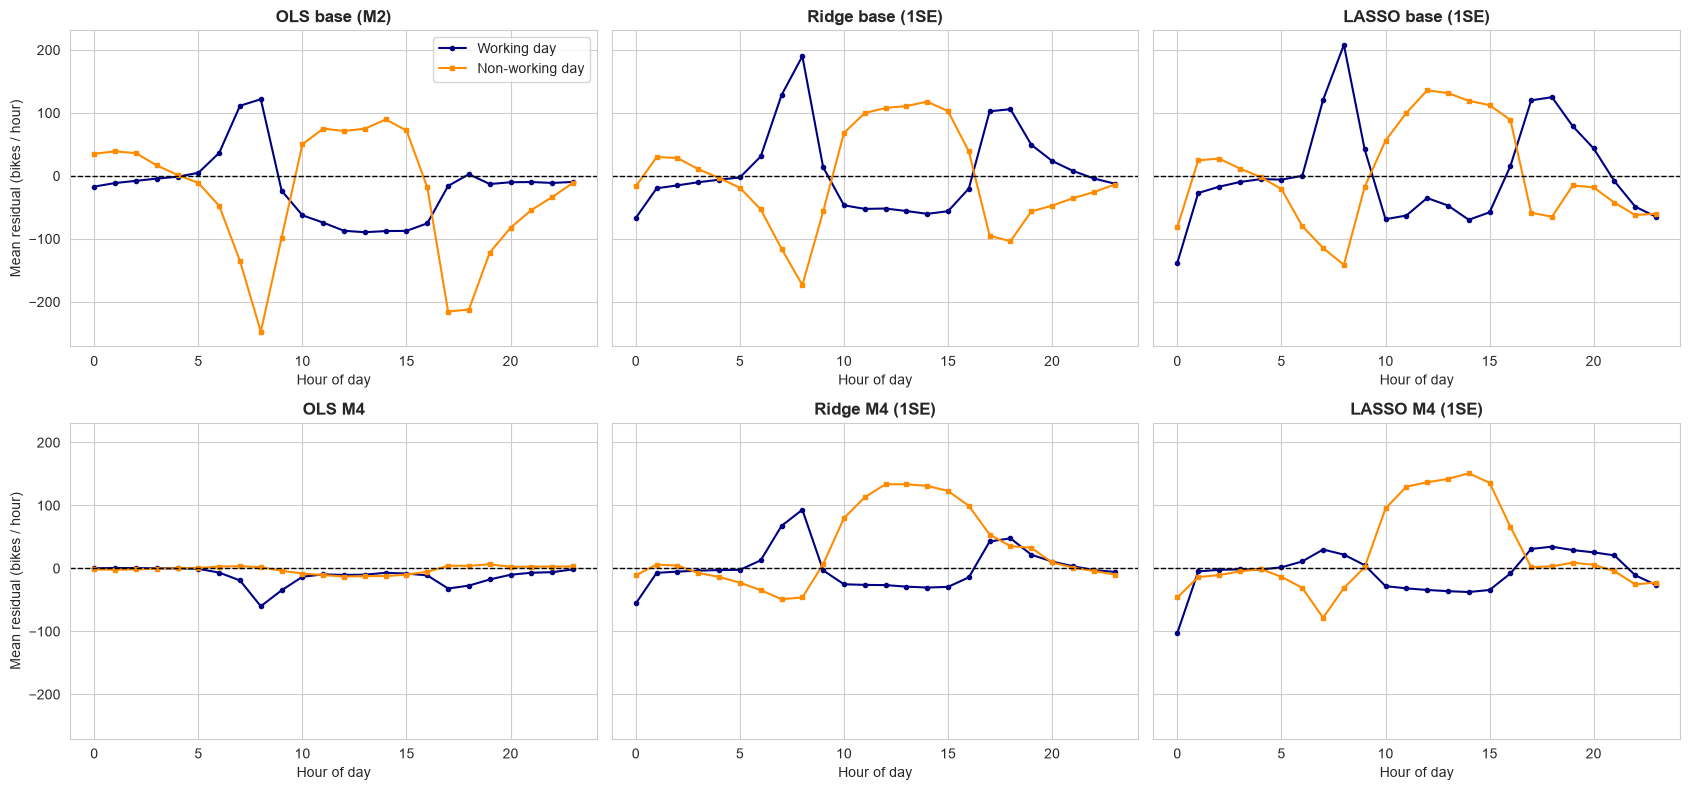

In [11]:
hour = (base_df[HR_COLS].to_numpy() * np.arange(1, 24)).sum(axis=1)   # hr_k dummies -> hour 0-23

DIAG_MODELS = {   # label -> (kind, space, alpha)
    'OLS base (M2)':       ('ols',   'base', None),
    'Ridge base (1SE)':    ('ridge', 'base', chosen[('ridge', 'base')]['1se']),
    'LASSO base (1SE)':    ('lasso', 'base', chosen[('lasso', 'base')]['1se']),
    'OLS M4':              ('ols',   'm4',   None),
    'Ridge M4 (1SE)':      ('ridge', 'm4',   chosen[('ridge', 'm4')]['1se']),
    'LASSO M4 (1SE)':      ('lasso', 'm4',   chosen[('lasso', 'm4')]['1se']),
}

diag = {}
for label, (kind, space, a) in DIAG_MODELS.items():
    X = FEATURE_SPACES[space]
    est = make_estimator(kind, a).fit(X, np.log(y_all))
    log_fit = est.predict(X)
    resid_log = np.log(y_all) - log_fit
    sigma2 = float(resid_log @ resid_log / (len(y_all) - n_params(est, X, kind)))
    count_pred = np.exp(log_fit + sigma2 / 2)
    diag[label] = {'log_fit': log_fit, 'resid_log': resid_log, 'count_pred': count_pred}

fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharey=True)
for ax, (label, d) in zip(axes.ravel(), diag.items()):
    res = pd.DataFrame({'hr': hour, 'workingday': base_df['workingday'].to_numpy(),
                        'resid': y_all - d['count_pred']})
    prof = res.groupby(['hr', 'workingday'])['resid'].mean().unstack()
    ax.plot(prof.index, prof[1], marker='o', ms=3, color='navy', label='Working day')
    ax.plot(prof.index, prof[0], marker='s', ms=3, color='darkorange', label='Non-working day')
    ax.axhline(0, color='black', linestyle='--', linewidth=1)
    ax.set_title(label, fontweight='bold'); ax.set_xlabel('Hour of day')
axes[0, 0].set_ylabel('Mean residual (bikes / hour)'); axes[1, 0].set_ylabel('Mean residual (bikes / hour)')
axes[0, 0].legend()
plt.tight_layout()
plt.show()

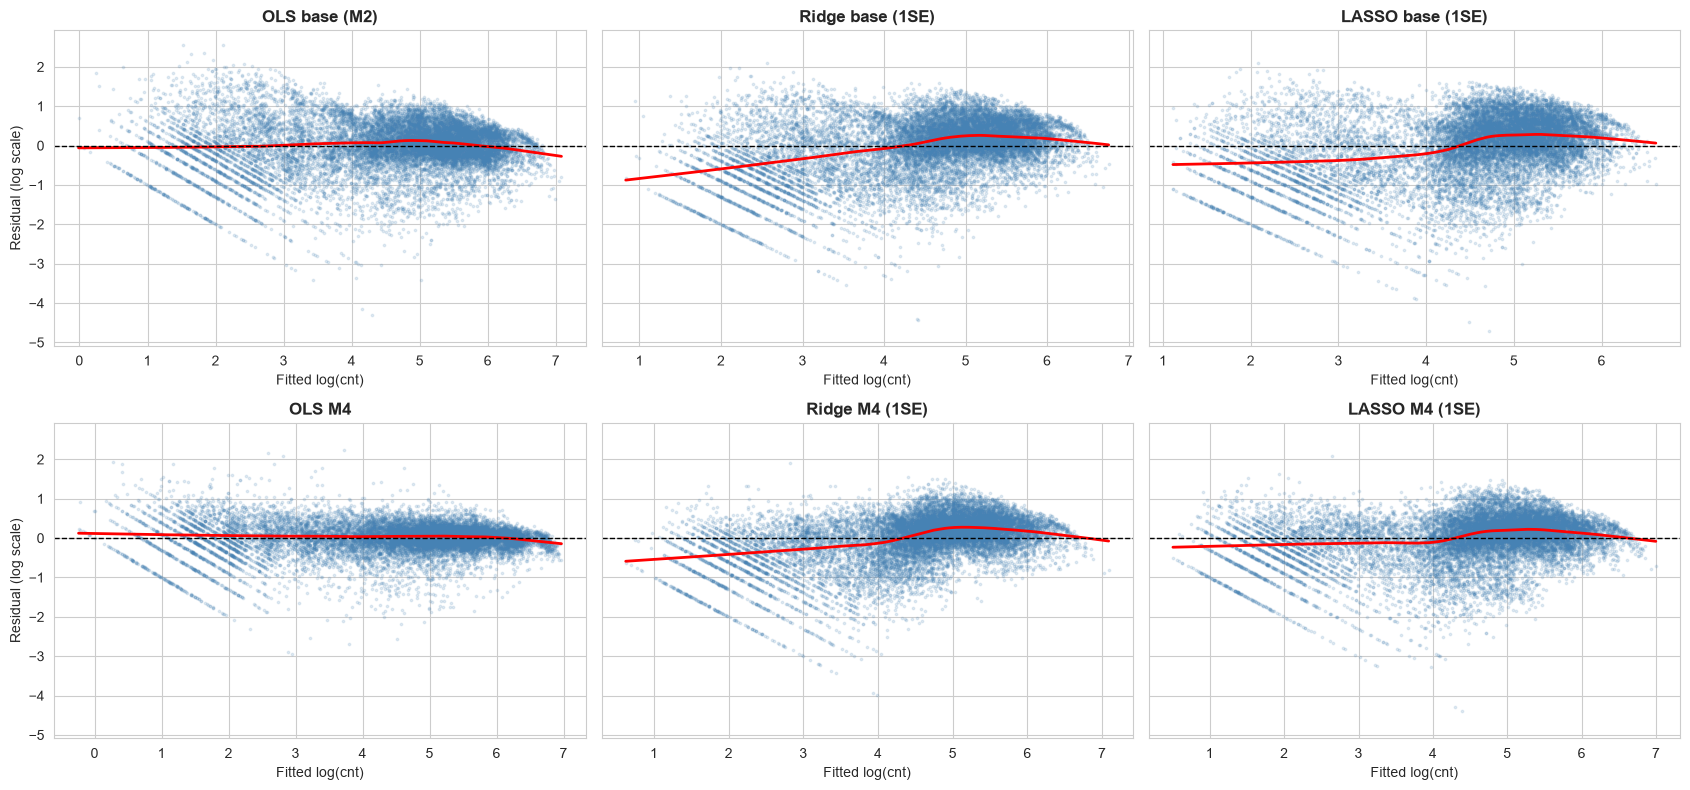

                  max_abs_mean_resid_by_hr_x_wd  lag1_resid_autocorr
OLS base (M2)                            247.44                 0.71
Ridge base (1SE)                         190.11                 0.74
LASSO base (1SE)                         208.23                 0.75
OLS M4                                    60.09                 0.52
Ridge M4 (1SE)                           133.85                 0.72
LASSO M4 (1SE)                           151.05                 0.66


In [12]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharey=True)
for ax, (label, d) in zip(axes.ravel(), diag.items()):
    lo = sm.nonparametric.lowess(d['resid_log'], d['log_fit'], frac=0.3)
    ax.scatter(d['log_fit'], d['resid_log'], s=3, alpha=0.15, color='steelblue')
    ax.plot(lo[:, 0], lo[:, 1], color='red', linewidth=2)
    ax.axhline(0, color='black', linestyle='--', linewidth=1)
    ax.set_title(label, fontweight='bold'); ax.set_xlabel('Fitted log(cnt)')
axes[0, 0].set_ylabel('Residual (log scale)'); axes[1, 0].set_ylabel('Residual (log scale)')
plt.tight_layout()
plt.show()

# Worst mean absolute hour x working-day residual (count scale), one number per model
summ = {}
for label, d in diag.items():
    res = pd.DataFrame({'hr': hour, 'wd': base_df['workingday'].to_numpy(), 'resid': y_all - d['count_pred']})
    summ[label] = {'max_abs_mean_resid_by_hr_x_wd': res.groupby(['hr', 'wd'])['resid'].mean().abs().max(),
                   'lag1_resid_autocorr': np.corrcoef(d['resid_log'][:-1], d['resid_log'][1:])[0, 1]}
print(pd.DataFrame(summ).T.round(2).to_string())

### Interpretation & Modeling Decisions: Shrinkage vs. Nonlinearity
**Author**: Lim Wei Lun Marcus

The penalised base models outperform OLS M2 on count-scale CV (RMSE 186 to 136 for Ridge and 142 for LASSO), but Section 6b.1 indicates this comes mainly from less over-prediction rather than lower variance, because their log-scale validation fit worsens. Shrinkage also cannot compensate for the structural bias of an additive model that lacks the relevant interaction: at $\lambda_{1\text{SE}}$, the largest mean hour-by-working-day residual stays large in the base space (about 190 for Ridge and 208 for LASSO, versus 247 for OLS M2). OLS M3 remains at 253.2 (Section 6b.2), so the squared terms do not reduce this pattern, while adding hr × workingday in OLS M4 lowers it to 60. The explicit interaction is therefore what removes the pattern. How much of that benefit survives depends on the penalty. LASSO M4 at $\lambda_{\min}$ reaches 48.2, lower than OLS M4, whereas regularized M4 at $\lambda_{1\text{SE}}$ sits at 134 to 151 because the heavier penalty shrinks both the interaction coefficients (35–40% of their near-OLS size) and the hour main effects (46–52%; Section 6b.4). The case for the squared terms rests on the Notebook 04 CV comparison (M3 vs M2), not on this notebook’s residual plots.

## 6. CV Results Package for Final Selection
*Code: Generated by AI Assistant*

All candidates on the shared folds with count-scale scores, plus the paired fold-by-fold gain against the matching OLS rung (Ridge/LASSO **base** vs M2; Ridge/LASSO **m4** vs M4). Per-fold MSEs are written to `data/cv_results_05_regularization.csv` for Notebook 06. Summaries use the Notebook 04 RMSE definition so the tables can be stacked. No test data is used.

In [13]:
def paired_gain(fold_a, fold_b):
    # Positive = model B has lower MSE than model A
    d = fold_a - fold_b
    se = d.std(ddof=1) / np.sqrt(len(d))
    return d.mean(), se, d.mean() / se, int((d > 0).sum())


cands = {}   # label -> (per-fold MSE array, reference rung)
for name, f in ref_folds.items():
    cands[f'{name} OLS'] = (f, None)
for (kind, space), c in chosen.items():
    ref = 'M2' if space == 'base' else 'M4'
    for rule in ['min', '1se']:
        cands[f'{kind.capitalize()} {space} ({rule})'] = (fold_store[(kind, space, c[rule])], ref)

rows = []
for label, (f, ref) in cands.items():
    s = summarise(f)
    row = {'model': label, **{k: s[k] for k in ['cv_rmse', 'se_rmse', 'cv_mse', 'se_mse']}}
    if ref is not None:
        g, gse, gz, nb = paired_gain(ref_folds[ref], f)
        row.update({'vs_OLS_rung': ref, 'gain_mse': g, 'gain_in_SEs': gz, 'folds_better': f'{nb}/{K}'})
    rows.append(row)
results_05 = pd.DataFrame(rows).set_index('model')
print("=== Candidate Summary (shared CV, count-scale) ===")
print(results_05.round(2).to_string())

# Export per-fold MSE for Notebook 06
export = pd.DataFrame([{'model': label, 'fold': i + 1, 'val_month': VAL_MONTHS[i], 'mse': m}
                       for label, (f, _) in cands.items() for i, m in enumerate(f)])
export.to_csv(DATA_DIR / 'cv_results_05_regularization.csv', index=False)
print(f"\nSaved {len(export)} rows to data/cv_results_05_regularization.csv")

=== Candidate Summary (shared CV, count-scale) ===
                  cv_rmse  se_rmse    cv_mse   se_mse vs_OLS_rung  gain_mse  gain_in_SEs folds_better
model                                                                                                
M1 OLS             130.86     7.19  17125.20  1882.65         NaN       NaN          NaN          NaN
M2 OLS             186.11    23.58  34635.54  8777.74         NaN       NaN          NaN          NaN
M3 OLS             151.75    16.84  23028.70  5110.11         NaN       NaN          NaN          NaN
M4 OLS             115.46    18.95  13330.00  4376.27         NaN       NaN          NaN          NaN
Ridge base (min)   135.53     6.89  18367.95  1868.57          M2  16267.60         1.95          6/8
Ridge base (1se)   136.80     6.71  18714.10  1835.15          M2  15921.45         1.71          6/8
Ridge m4 (min)     115.46    18.95  13330.00  4376.27          M4     -0.00        -1.41          2/8
Ridge m4 (1se)     126.93     8

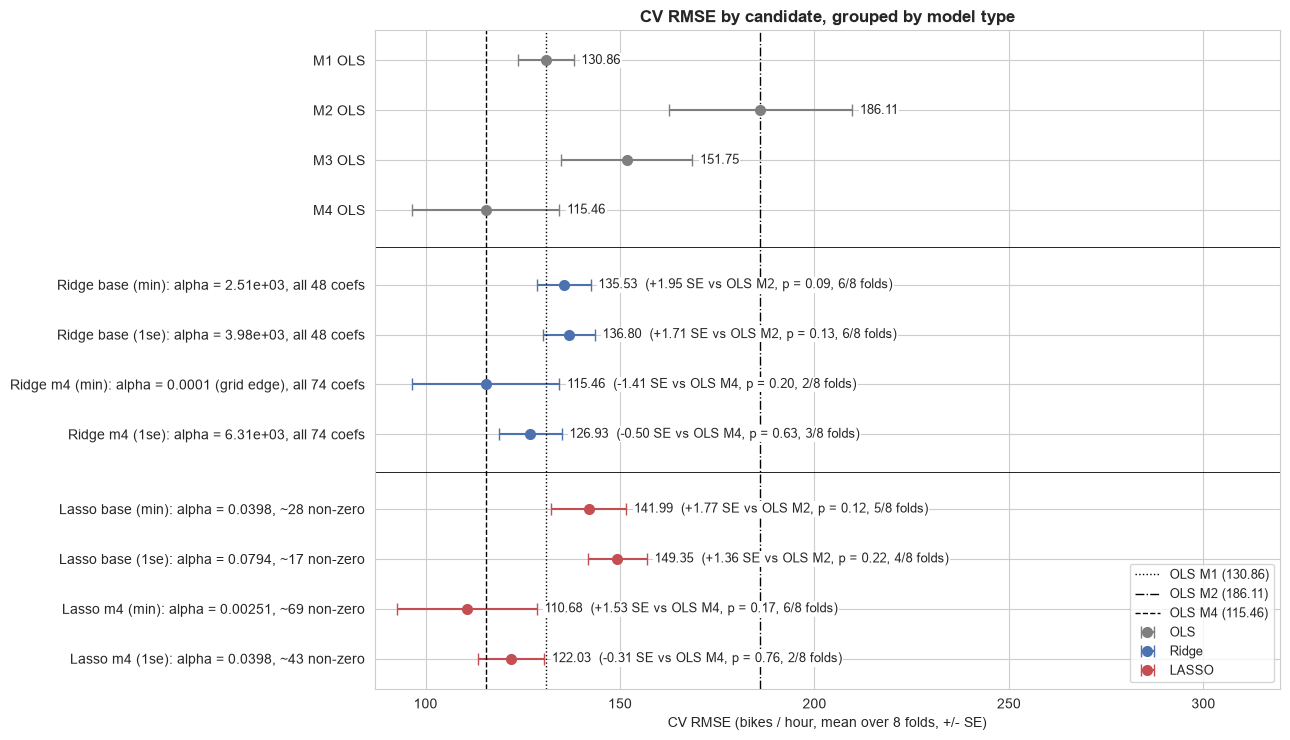

In [14]:
# CV RMSE (+/- SE) for every candidate, grouped by model type. Labels: alpha and coefficients; right-hand text:
# paired gain against the matching OLS rung (base -> M2, m4 -> M4), two-sided t_7 p-value, folds better
from scipy import stats as scipy_stats

GROUPS = [('OLS', [f'{m} OLS' for m in ['M1', 'M2', 'M3', 'M4']], '#7f7f7f'),
          ('Ridge', [f'Ridge {s} ({r})' for s in ['base', 'm4'] for r in ['min', '1se']], '#4c72b0'),
          ('LASSO', [f'Lasso {s} ({r})' for s in ['base', 'm4'] for r in ['min', '1se']], '#c44e52')]


def candidate_label(name):
    if name.endswith('OLS'):
        return name
    kind, space, rule = name.split()
    row = tuning_summary.loc[(f'{kind.lower()}-{space}', rule.strip('()'))]
    coefs = (f"all {row['mean_nonzero_coefs']:.0f} coefs" if kind == 'Ridge'
             else f"~{row['mean_nonzero_coefs']:.0f} non-zero")
    edge = ' (grid edge)' if row['alpha'] in (ALPHA_GRIDS[kind.lower()][0], ALPHA_GRIDS[kind.lower()][-1]) else ''
    return f"{name}: alpha = {row['alpha']:.3g}{edge}, {coefs}"


def gain_text(name):
    r = results_05.loc[name]
    if pd.isna(r['vs_OLS_rung']):
        return f"{r['cv_rmse']:.2f}"
    p = 2 * scipy_stats.t.sf(abs(r['gain_in_SEs']), K - 1)
    return f"{r['cv_rmse']:.2f}  ({r['gain_in_SEs']:+.2f} SE vs OLS {r['vs_OLS_rung']}, p = {p:.2f}, {r['folds_better']} folds)"


fig, ax = plt.subplots(figsize=(13, 7.5))
y, ticks, labels = 0, [], []
for g, (group, names, color) in enumerate(GROUPS):
    if g:
        ax.axhline(y - 0.25, color='black', linewidth=0.6)   # separator between model types
        y += 0.5
    for i, name in enumerate(names):
        r = results_05.loc[name]
        ax.errorbar(r['cv_rmse'], y, xerr=r['se_rmse'], fmt='o', color=color, capsize=4, markersize=7,
                    label=group if i == 0 else None)
        ax.text(r['cv_rmse'] + r['se_rmse'] + 2, y, gain_text(name), va='center', fontsize=9, zorder=5,
                bbox=dict(facecolor='white', edgecolor='none', pad=1))
        ticks.append(y); labels.append(candidate_label(name))
        y += 1
for rung, ls in [('M1', ':'), ('M2', '-.'), ('M4', '--')]:
    ax.axvline(results_05.loc[f'{rung} OLS', 'cv_rmse'], color='black', linestyle=ls, linewidth=1,
               label=f'OLS {rung} ({results_05.loc[f"{rung} OLS", "cv_rmse"]:.2f})')
ax.set_yticks(ticks, labels)
ax.invert_yaxis()
ax.set_xlim(right=(results_05['cv_rmse'] + results_05['se_rmse']).max() + 110)
ax.set_xlabel('CV RMSE (bikes / hour, mean over 8 folds, +/- SE)')
ax.set_title('CV RMSE by candidate, grouped by model type', fontweight='bold')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join('..', 'figures', '12_cv_rmse_by_candidate.png'), dpi=150, bbox_inches='tight')
plt.show()

## 6b. Supporting Checks
*Code: Generated by AI Assistant*

Additional outputs on the training set only. Nothing here is exported or added to the candidate list, and no test data is used.
- **6b.1**: validation MSE on the log scale and mean predicted / actual, by model.
- **6b.2**: worst hour $\times$ working-day residual for OLS M3 and LASSO M4 at $\lambda_{\min}$.
- **6b.3**: paired gain by validation month, with and without May, and two-sided $t_7$ p-values.
- **6b.4**: size of each coefficient group relative to the near-OLS Ridge fit.
- **6b.5**: forward-chained tuning ($\lambda$ chosen from earlier folds only, scored on the next fold).
- **6b.6**: sensitivity of the M4-space models to centring the squared terms inside each training fold.
- **6b.7**: chart of 6b.5 and 6b.6, saved to `figures/14_tuning_optimism_and_centring.png`.

In [15]:
# 6b.1 Log-scale validation fit and mean predicted / actual (mean across CV folds)
models = {'OLS M2': ('ols', 'base', None),
          'Ridge base (min)': ('ridge', 'base', chosen[('ridge', 'base')]['min']),
          'LASSO base (min)': ('lasso', 'base', chosen[('lasso', 'base')]['min']),
          'OLS M4': ('ols', 'm4', None),
          'LASSO M4 (min)': ('lasso', 'm4', chosen[('lasso', 'm4')]['min'])}
rows = []
for label, (kind, space, a) in models.items():
    X = FEATURE_SPACES[space]
    for tr, va in cv_splitter.split(base_df):
        pred, est = fit_predict_count(kind, a, X.iloc[tr], y_all[tr], X.iloc[va])
        rows.append({'model': label,
                     'val_log_mse': np.mean((np.log(y_all[va]) - est.predict(X.iloc[va])) ** 2),
                     'pred_over_actual': pred.mean() / y_all[va].mean()})
print(pd.DataFrame(rows).groupby('model', sort=False).mean().round(3).to_string())

                  val_log_mse  pred_over_actual
model                                          
OLS M2                  0.404             1.319
Ridge base (min)        0.478             0.938
LASSO base (min)        0.501             0.950
OLS M4                  0.153             1.197
LASSO M4 (min)          0.146             1.139


In [16]:
# 6b.2 Worst mean absolute hour x working-day residual (count scale, full training fit)
for label, (kind, X, a) in {'OLS M3': ('ols', X_m3, None),
                            'LASSO M4 (min)': ('lasso', X_m4, chosen[('lasso', 'm4')]['min'])}.items():
    est = make_estimator(kind, a).fit(X, np.log(y_all))
    fit = est.predict(X)
    r = np.log(y_all) - fit
    s2 = r @ r / (len(y_all) - n_params(est, X, kind))
    res = pd.Series(y_all - np.exp(fit + s2 / 2))
    print(f"{label}: {res.groupby([hour, base_df['workingday'].to_numpy()]).mean().abs().max():.1f}")

OLS M3: 253.2
LASSO M4 (min): 48.2


In [17]:
# 6b.3 Paired MSE gain against the matching OLS rung, by validation month (positive = model has lower MSE)
from scipy import stats as scipy_stats

penalised = {label: v for label, v in cands.items() if v[1] is not None}
month_gain = pd.DataFrame({label: ref_folds[ref] - f for label, (f, ref) in penalised.items()}, index=VAL_MONTHS)
print(month_gain.round(0).astype(int).T.to_string())

rows = {}
for label in month_gain:
    d = month_gain[label]
    t_stat = d.mean() / (d.std(ddof=1) / np.sqrt(K))
    rows[label] = {'mean_gain': d.mean(), 'mean_gain_excl_May': d.drop('2012-05').mean(),
                   't': t_stat, 'p_t7': 2 * scipy_stats.t.sf(abs(t_stat), K - 1), 'folds_better': int((d > 0).sum())}
print()
print(pd.DataFrame(rows).T.round(3).to_string())

d = fold_store[('lasso', 'm4', chosen[('lasso', 'm4')]['min'])] - fold_store[('lasso', 'm4', chosen[('lasso', 'm4')]['1se'])]
t_stat = d.mean() / (d.std(ddof=1) / np.sqrt(K))
print(f"\nLASSO M4 min vs 1se: mean gain = {d.mean():.1f}, t = {t_stat:.2f}, 1se better in {int((d > 0).sum())}/{K} folds")

                  2012-02  2012-03  2012-04  2012-05  2012-06  2012-07  2012-08  2012-09
Ridge base (min)    -3101   -13607     5690    57598    40763    25017    12098     5684
Ridge base (1se)    -4551   -18122     2137    60093    45098    27588    11312     3818
Ridge m4 (min)          0        0        0        0        0        0        0        0
Ridge m4 (1se)      -7760   -22648   -10764    30313     2119     1555    -2272   -12797
Lasso base (min)    -2145    -9561     2684    58458    39215    15351    12163     -366
Lasso base (1se)    -4249   -15831    -4373    54169    43550    23955     9464    -8043
Lasso m4 (min)       1103    -1113     1695     5339     -924      605     1213      714
Lasso m4 (1se)      -4630   -12777    -7185    30510     1843    -4631     -265   -15356

                  mean_gain  mean_gain_excl_May      t   p_t7  folds_better
Ridge base (min)  16267.597           10363.233  1.951  0.092           6.0
Ridge base (1se)  15921.447            9611.21

In [18]:
# 6b.4 Sum of |standardised coefficient| by group, relative to Ridge M4 at the smallest grid alpha (near OLS)
ref_coef = paths[('ridge', 'm4')].iloc[0]
INTER_COLS = [c for c in X_m4.columns if ':workingday' in c]
OTHER_COLS = [c for c in X_m4.columns if c not in INTER_COLS + HR_COLS]
rows = {}
for label, (kind, rule) in {'Ridge M4 (1se)': ('ridge', '1se'), 'LASSO M4 (1se)': ('lasso', '1se'),
                            'LASSO M4 (min)': ('lasso', 'min')}.items():
    c = paths[(kind, 'm4')].loc[chosen[(kind, 'm4')][rule]]
    rows[label] = {g: c[cols].abs().sum() / ref_coef[cols].abs().sum()
                   for g, cols in [('hr x workingday', INTER_COLS), ('hr main effects', HR_COLS), ('all other', OTHER_COLS)]}
print(pd.DataFrame(rows).T.round(3).to_string())

                hr x workingday  hr main effects  all other
Ridge M4 (1se)            0.395            0.518      0.301
LASSO M4 (1se)            0.345            0.463      0.205
LASSO M4 (min)            0.773            0.994      0.699


In [19]:
# 6b.5 Forward-chained tuning, LASSO M4: lambda chosen on earlier folds only (validation months 3 to 8)
A = ALPHA_GRIDS['lasso']
M = np.array([fold_store[('lasso', 'm4', a)] for a in A])
picks = [M[:, :i].mean(axis=1).argmin() for i in range(2, K)]
honest = np.array([M[j, i] for j, i in zip(picks, range(2, K))])
print('Validation months:', VAL_MONTHS[2:])
print('lambda picks     :', np.round(A[picks], 4))
print('Mean MSE, chained LASSO M4:', round(honest.mean()),
      '| fixed lambda_min:', round(fold_store[('lasso', 'm4', chosen[('lasso', 'm4')]['min'])][2:].mean()),
      '| OLS M4:', round(ref_folds['M4'][2:].mean()))

Validation months: ['2012-04', '2012-05', '2012-06', '2012-07', '2012-08', '2012-09']
lambda picks     : [0.0013 0.0018 0.0141 0.02   0.02   0.02  ]
Mean MSE, chained LASSO M4: 18131 | fixed lambda_min: 15220 | OLS M4: 16660


In [20]:
# 6b.6 M4 space with squared terms centred on the training-fold mean (sensitivity only, not exported)
def centred_m4(tr):
    X = X_base.copy()
    for c in POLY_COLS:
        X[f'{c}^2'] = (X[c] - X[c].iloc[tr].mean()) ** 2
    return add_hr_workingday(X)


CENTRED_FOLDS = [(tr, va, centred_m4(tr)) for tr, va in cv_splitter.split(base_df)]


def cv_centred(kind, alpha):
    return np.array([np.mean((y_all[va] - fit_predict_count(kind, alpha, X.iloc[tr], y_all[tr], X.iloc[va])[0]) ** 2)
                     for tr, va, X in CENTRED_FOLDS])


print(f"OLS M4, centred squares: CV MSE = {cv_centred('ols', None).mean():.2f} (raw squares: {ref_folds['M4'].mean():.2f})\n")

rows = []
for kind in ['ridge', 'lasso']:
    folds_by_alpha = {a: cv_centred(kind, a) for a in ALPHA_GRIDS[kind]}
    curve = pd.DataFrame({a: summarise(f) for a, f in folds_by_alpha.items()}).T
    a_min, a_1se = pick_lambdas(curve)
    for rule, a in [('min', a_min), ('1se', a_1se)]:
        g, gse, gz, nb = paired_gain(ref_folds['M4'], folds_by_alpha[a])
        rows.append({'model': f'{kind}-m4-centred', 'rule': rule, 'alpha': a, 'cv_rmse': curve.loc[a, 'cv_rmse'],
                     'cv_mse': curve.loc[a, 'cv_mse'], 'se_mse': curve.loc[a, 'se_mse'],
                     'raw_squares_cv_rmse': cv_curves[(kind, 'm4')].loc[chosen[(kind, 'm4')][rule], 'cv_rmse'],
                     'gain_vs_M4': g, 'gain_in_SEs': gz, 'folds_better': f'{nb}/{K}'})
print(pd.DataFrame(rows).set_index(['model', 'rule']).round(4).to_string())

OLS M4, centred squares: CV MSE = 13330.00 (raw squares: 13330.00)



                           alpha  cv_rmse     cv_mse     se_mse  raw_squares_cv_rmse  gain_vs_M4  gain_in_SEs folds_better
model            rule                                                                                                     
ridge-m4-centred min   1000.0000  87.7026  7691.7494  1079.4814             115.4556   5638.2538       1.4953          6/8
                 1se   1584.8932  90.0745  8113.4183  1071.7522             126.9323   5216.5849       1.1504          4/8
lasso-m4-centred min      0.0100  86.5779  7495.7301  1136.9618             110.6843   5834.2732       1.7449          5/8
                 1se      0.0200  92.1383  8489.4617   859.6660             122.0306   4840.5416       1.0729          4/8


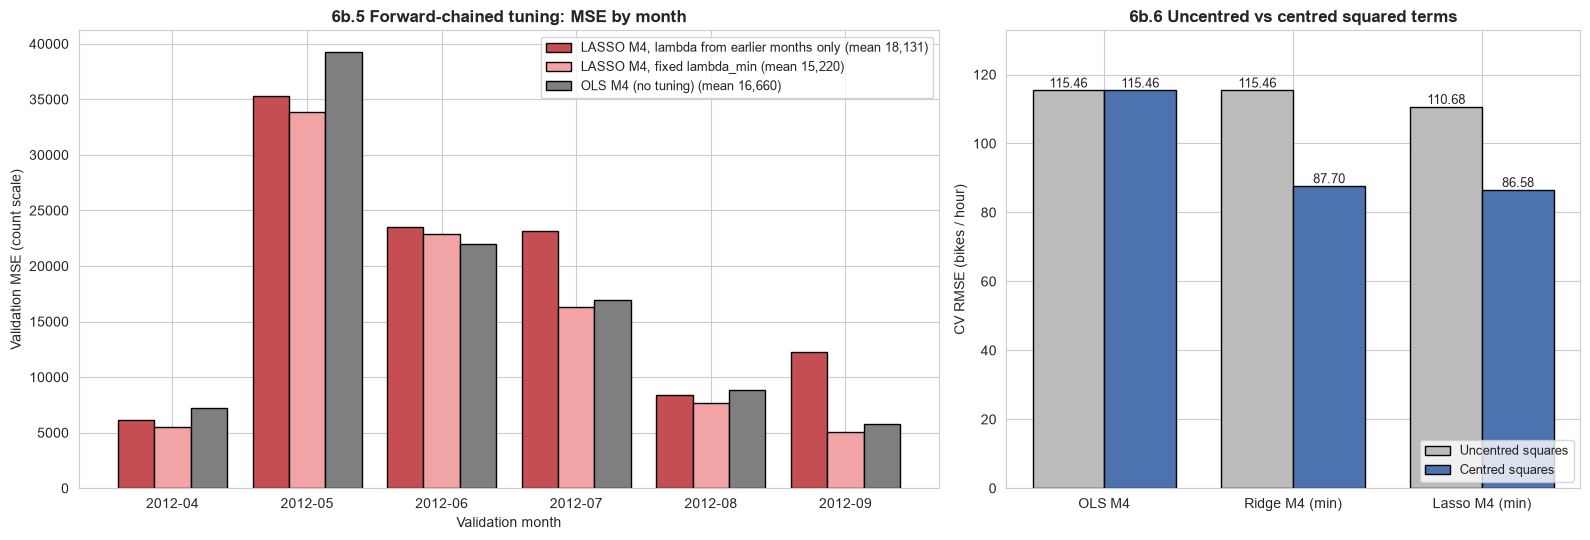

         LASSO M4, lambda from earlier months only  LASSO M4, fixed lambda_min  OLS M4 (no tuning)
2012-04                                       6136                        5488                7183
2012-05                                      35306                       33897               39236
2012-06                                      23497                       22873               21949
2012-07                                      23166                       16320               16926
2012-08                                       8422                        7633                8846
2012-09                                      12259                        5106                5819
                Uncentred squares  Centred squares
OLS M4                     115.46           115.46
Ridge M4 (min)             115.46            87.70
Lasso M4 (min)             110.68            86.58


In [21]:
# 6b.7 Chart of 6b.5 (forward-chained tuning, by month) and 6b.6 (uncentred vs centred squared terms)
lasso_min = chosen[('lasso', 'm4')]['min']
monthly = pd.DataFrame({
    'LASSO M4, lambda from earlier months only': honest,
    'LASSO M4, fixed lambda_min': fold_store[('lasso', 'm4', lasso_min)][2:],
    'OLS M4 (no tuning)': ref_folds['M4'][2:],
}, index=VAL_MONTHS[2:])

centring = pd.DataFrame({
    'Uncentred squares': [summarise(ref_folds['M4'])['cv_rmse']] + [r['raw_squares_cv_rmse'] for r in rows if r['rule'] == 'min'],
    'Centred squares': [summarise(cv_centred('ols', None))['cv_rmse']] + [r['cv_rmse'] for r in rows if r['rule'] == 'min'],
}, index=['OLS M4'] + [f"{r['model'].split('-')[0].capitalize()} M4 (min)" for r in rows if r['rule'] == 'min'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={'width_ratios': [3, 2]})
w = 0.27
x = np.arange(len(monthly))
for j, (col, color) in enumerate(zip(monthly.columns, ['#c44e52', '#f2a3a5', '#7f7f7f'])):
    ax1.bar(x + (j - 1) * w, monthly[col], w, color=color, edgecolor='black',
            label=f'{col} (mean {monthly[col].mean():,.0f})')
ax1.set_xticks(x, monthly.index)
ax1.set_xlabel('Validation month'); ax1.set_ylabel('Validation MSE (count scale)')
ax1.set_title('6b.5 Forward-chained tuning: MSE by month', fontweight='bold')
ax1.legend(fontsize=9)

x = np.arange(len(centring))
for j, (col, color) in enumerate(zip(centring.columns, ['#bbbbbb', '#4c72b0'])):
    bars = ax2.bar(x + (j - 0.5) * 0.38, centring[col], 0.38, color=color, edgecolor='black', label=col)
    ax2.bar_label(bars, fmt='%.2f', fontsize=9)
ax2.set_xticks(x, centring.index)
ax2.set_ylabel('CV RMSE (bikes / hour)')
ax2.set_title('6b.6 Uncentred vs centred squared terms', fontweight='bold')
ax2.set_ylim(0, centring.to_numpy().max() * 1.15)
ax2.legend(fontsize=9, loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join('..', 'figures', '14_tuning_optimism_and_centring.png'), dpi=150, bbox_inches='tight')
plt.show()
print(monthly.round(0).astype(int).to_string())
print(centring.round(2).to_string())

### Interpretation & Modeling Decisions: CV Results Package
**Author**: Lim Wei Lun Marcus

We export the per-fold count-scale MSE results to data/cv_results_05_regularization.csv for model selection in Notebook 06. Notebook 04 did not export a CSV, but the metric definitions ($\text{CV RMSE} = \sqrt{\text{mean fold MSE}}$, $\text{SE} = \text{SD}/\sqrt{8}$) match its formulation, so the comparison is unified. LASSO M4 at $\lambda_{\min}$ has the lowest CV RMSE (110.68 vs 115.46 for OLS M4), but the gain is within noise (1.53 paired SE, p = 0.17), so we propose carrying both LASSO M4 and OLS M4 into Notebook 06 rather than treating LASSO M4 as a clear winner.

We favour $\lambda_{\min}$ over $\lambda_{1\text{SE}}$ for this comparison because it has the lower mean CV error and keeps the hour-by-working-day residual low (48 vs 151), and the 1SE band is wide here. Notebook 06 allows either lowest mean or the 1-SE rule, and under a cross-model 1-SE threshold (16,213 MSE) LASSO M4 at $\lambda_{1\text{SE}}$ (43 coefficients, 14,891 MSE) would remain eligible, so the rule must be fixed before the test set is opened.

Two caveats apply. First, $\lambda$ was tuned on the same expanding-window folds used to report the CV MSE, so these scores are optimistic, possibly by a material amount: choosing $\lambda$ from earlier folds only gives LASSO M4 a mean MSE of 18,131 over April to September, against 16,660 for OLS M4 and 15,220 with the fixed $\lambda_{\min}$ (Section 6b.5). This rests on only six folds, so it is a warning rather than evidence that OLS is better. Second, these scores use uncentred squared terms, and the penalised results are sensitive to that choice (Section 6b.6), so the parameterisation must also be fixed before Notebook 06.